In [1]:
"""Complex time evolution"""

__author__    = "Valentyn Abramov"
__credit__    = ["Valentyn Abramov", "Evgueni Dinvay"]

__date__      = "2026-10-02"

# Time evolution in the complex plane

A complex wave function drawn as a curve in $(x, \mathrm{Re}\,\Psi, \mathrm{Im}\,\Psi)$ at every
time step. The propagation is the one of `harmonic_oscillator_evolution.ipynb`, for
\begin{equation}
    i \partial_t \Psi
    =
    \left( - \partial_x^2 + V(x) \right) \Psi
    ,
\end{equation}
where a wave packet with wave number $k$ moves with velocity $2k$.

In [2]:
import os
import tempfile
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation, PillowWriter
from IPython.display import Image
from vampyr import vampyr1d as vp1
from vampyr import LegendreBasis

precision = 1.0e-5
finest_scale = 9
mra = vp1.MultiResolutionAnalysis(vp1.BoundingBox(0), LegendreBasis(5))
Pc = vp1.ScalingProjector(mra, prec = precision, dtype = complex)

x_vec = np.linspace(0, 0.9999, 1000)

`ChinChenA`, `MultiplicationOperator` and the `create_*` functions are copied from
`harmonic_oscillator_evolution.ipynb`.

In [3]:
class ChinChenA(object):
    def __init__(self, expA, expB, exp_tildeB):
        self.expA = expA
        self.expB = expB
        self.exp_tildeB = exp_tildeB
    def __call__(self, u):
        u = self.expB(u)        # 1/6*dt
        u = self.expA(u)        # 1/2*dt
        u = self.exp_tildeB(u)  # 2/3*dt
        u = self.expA(u)        # 1/2*dt
        u = self.expB(u)        # 1/6*dt
        return u

class MultiplicationOperator(object):
    def __init__(self, function):
        self.function = function
    def __call__(self, function):
        return self.function * function

def create_unitary_potential_operator(Pc, V, t):
    def kernel(x):
        return np.exp(-1j * V(x) * t)
    return MultiplicationOperator(Pc(kernel))

def create_unitary_kinetic_operator(mra, precision, time, finest_scale):
    return vp1.TimeEvolutionOperator(mra, precision, time, finest_scale)

def harmonic_step(V0, x1, time_step):
    def V(x):
        return V0 * (x[0] - x1)**2
    def tilde_V(x):
        A = V0 - ( time_step * V0 )**2 / 6.0
        return A * (x[0] - x1)**2
    return ChinChenA(
        expA = create_unitary_kinetic_operator(mra, precision, time_step / 2, finest_scale),
        expB = create_unitary_potential_operator(Pc, V, time_step / 6),
        exp_tildeB = create_unitary_potential_operator(Pc, tilde_V, 2 * time_step / 3)
    )

def free_step(time_step):
    return create_unitary_kinetic_operator(mra, precision, time_step, finest_scale)

In [4]:
def packet(x0, sigma, k = 0.0):
    alpha = (2 * np.pi * sigma**2)**(-1/4)
    return lambda x: alpha * np.exp(-(x - x0)**2 / (4 * sigma**2) + 1j * k * (x - x0))

def project(f):
    return Pc(lambda r: complex(f(r[0])))

def evolve(psi0, step, n_steps, keep = ()):
    frames, kept, psi = [], {}, psi0
    for n in range(n_steps + 1):
        frames.append(np.array([psi([x]) for x in x_vec]))
        if n in keep:
            kept[n] = psi
        if n < n_steps:
            psi = step(psi)
    return frames, kept

def animate(frames, title, fps = 10):
    lim = 1.1 * max(np.abs(f).max() for f in frames)
    fig = plt.figure(figsize = (6, 4.5))
    ax = fig.add_subplot(projection = '3d')
    ax.set(xlim = (0, 1), ylim = (-lim, lim), zlim = (-lim, lim),
           xlabel = 'x', ylabel = r'Re $\Psi$', zlabel = r'Im $\Psi$', title = title)
    line, = ax.plot(x_vec, frames[0].real, frames[0].imag, lw = 1)
    def draw(n):
        line.set_data(x_vec, frames[n].real)
        line.set_3d_properties(frames[n].imag)
        return line,
    animation = FuncAnimation(fig, draw, frames = len(frames))
    with tempfile.TemporaryDirectory() as tmp:
        path = os.path.join(tmp, 'animation.gif')
        animation.save(path, writer = PillowWriter(fps = fps), dpi = 72)
        with open(path, 'rb') as f:
            gif = f.read()
    plt.close(fig)
    return Image(data = gif, format = 'gif')

The displaced Gaussian of `harmonic_oscillator_evolution.ipynb`. Since
$\Psi(t_{\text{period}}) = -\Psi_0$, the animation covers two periods, so that it loops.

||Psi(t_period) + Psi_0|| = 1.54e-04


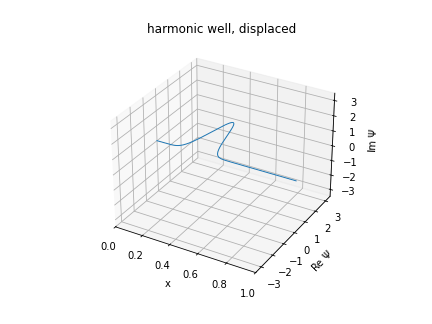

In [5]:
x0 = 0.3
sigma = 0.04
x1 = 0.5
V0 = 25000
N = 10
t_period = np.pi / np.sqrt(V0)
time_step = 0.5 * t_period / N

step_ho = harmonic_step(V0, x1, time_step)

psi0 = project(packet(x0, sigma))
frames, kept = evolve(psi0, step_ho, 4 * N, keep = (2 * N,))

print(f"||Psi(t_period) + Psi_0|| = {(kept[2 * N] + psi0).norm():.2e}")
animate(frames[:-1], 'harmonic well, displaced')

The same well, with the Gaussian started at the bottom and multiplied by $e^{ikx}$.
Its width $\sigma = (2 \sqrt{V_0})^{-1/2}$ is that of the ground state, so it oscillates
without changing shape. After half a period it is mirrored about $x_1$, with the momentum
reversed:
\begin{equation}
    \Psi(x, t_{\text{period}} / 2) = -i \Psi_0(2 x_1 - x)
    .
\end{equation}

||Psi(t_period / 2) + i Psi_0(2 x1 - x)|| = 2.07e-05
||Psi(t_period) + Psi_0|| = 3.53e-05


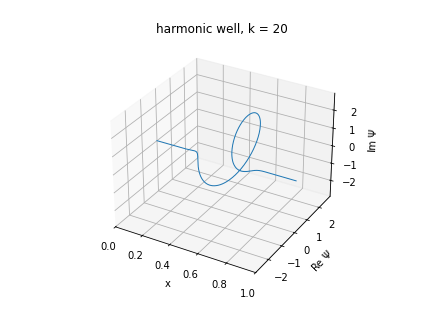

In [6]:
k = 20
sigma_coh = (2 * np.sqrt(V0))**(-1/2)
push0 = packet(x1, sigma_coh, k)

psi0 = project(push0)
mirror = project(lambda x: push0(2 * x1 - x))
frames, kept = evolve(psi0, step_ho, 4 * N, keep = (N, 2 * N))

print(f"||Psi(t_period / 2) + i Psi_0(2 x1 - x)|| = {(kept[N] + 1j * mirror).norm():.2e}")
print(f"||Psi(t_period) + Psi_0|| = {(kept[2 * N] + psi0).norm():.2e}")
animate(frames[:-1], f'harmonic well, k = {k}')

A free Gaussian. Each step is one application of the free propagator, and the exact
solution is
\begin{equation}
    \Psi(x, t)
    =
    \alpha \sqrt{\frac{s}{s + 4it}}
    \exp \left( - \frac{(x - x_0 - 2kt)^2}{s + 4it} + ik(x - x_0) - ik^2 t \right)
    , \quad
    s = 4 \sigma^2
    .
\end{equation}
The operator acts on $[0, 1]$ only, so the packet is kept away from the edges.

||Psi - Psi_exact|| at t = 2.0e-03: 2.96e-05


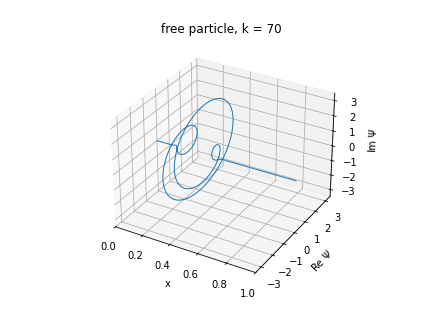

In [7]:
x0, sigma, k = 0.3, 0.04, 70
dt, n_steps = 1.0e-4, 20

def free_exact(t):
    s = 4 * sigma**2
    alpha = (2 * np.pi * sigma**2)**(-1/4)
    return lambda x: alpha * np.sqrt(s / (s + 4j * t)) * np.exp(
        -(x - x0 - 2 * k * t)**2 / (s + 4j * t) + 1j * k * (x - x0) - 1j * k**2 * t)

psi0 = project(packet(x0, sigma, k))
frames, kept = evolve(psi0, free_step(dt), n_steps, keep = (n_steps,))

t = n_steps * dt
print(f"||Psi - Psi_exact|| at t = {t:.1e}: {(kept[n_steps] - project(free_exact(t))).norm():.2e}")
animate(frames, f'free particle, k = {k}', fps = 8)